# Task 3: Baseline Regression Model

### Barakah TechLabs – Applied Data Scientist Internship

**Dataset:** California Housing Dataset  
**Models:** Linear Regression, Random Forest Regressor  
**Evaluation Metrics:** MAE, RMSE

## 1. Import Required Libraries

The following Python libraries are used for data manipulation, visualization, and machine learning.

In [23]:
from sklearn.datasets import fetch_california_housing


## 2. Dataset Loading

The California Housing dataset is loaded using Scikit-learn. The dataset contains housing-related features used to predict the median house value.

In [5]:
# Load California Housing Dataset

housing = fetch_california_housing(as_frame=True)

df = housing.frame

print("Dataset loaded successfully!")
print("Shape:", df.shape)

df.head()

Dataset loaded successfully!
Shape: (20640, 9)


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,3.413
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,3.422


## 3. Exploratory Data Analysis

Before training the models, the dataset is examined to understand its structure, statistical characteristics, missing values, target distribution, and feature relationships.

print("Dataset Information:")
print(df.info())

print("\nMissing Values:")
print(df.isnull().sum())

print("\nStatistical Summary:")
df.describe()

### 3.1 Features and Target Variable

The `MedHouseVal` column is used as the continuous target variable, while the remaining columns are used as input features.

In [7]:
# Separate features and target

X = df.drop("MedHouseVal", axis=1)
y = df["MedHouseVal"]

print("Features:")
print(X.columns.tolist())

print("\nTarget:")
print(y.name)

print("\nNumber of features:", X.shape[1])
print("Number of records:", X.shape[0])

Features:
['MedInc', 'HouseAge', 'AveRooms', 'AveBedrms', 'Population', 'AveOccup', 'Latitude', 'Longitude']

Target:
MedHouseVal

Number of features: 8
Number of records: 20640


### 3.2 Target Variable Distribution

The distribution of the target variable is visualized to understand the range and overall pattern of median house values.

In [8]:
# Distribution of target variable

plt.figure(figsize=(10, 6))

sns.histplot(y, bins=30, kde=True)

plt.title("Distribution of House Prices")
plt.xlabel("Median House Value")
plt.ylabel("Frequency")

plt.show()

NameError: name 'plt' is not defined

In [9]:
# Import required libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error

print("All libraries imported successfully!")

All libraries imported successfully!


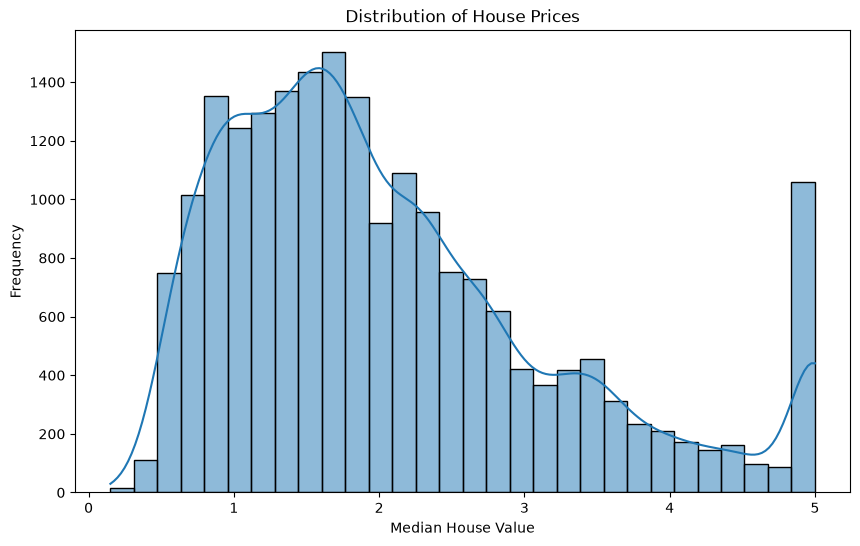

In [10]:
# Distribution of target variable

plt.figure(figsize=(10, 6))

sns.histplot(y, bins=30, kde=True)

plt.title("Distribution of House Prices")
plt.xlabel("Median House Value")
plt.ylabel("Frequency")

plt.show()

### 3.3 Correlation Analysis

A correlation matrix is used to examine relationships between the numerical features and the target variable.

# Correlation Matrix

plt.figure(figsize=(12, 8))

sns.heatmap(
    df.corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Matrix")
plt.show()

### 3.4 Missing Value Analysis

Missing values are checked before model training to ensure that the dataset is suitable for regression modeling.

In [12]:
# Check for missing values

missing_values = df.isnull().sum()

print("Missing values in each column:")
print(missing_values)

print("\nTotal missing values:", missing_values.sum())

Missing values in each column:
MedInc         0
HouseAge       0
AveRooms       0
AveBedrms      0
Population     0
AveOccup       0
Latitude       0
Longitude      0
MedHouseVal    0
dtype: int64

Total missing values: 0


## 4. Model Development

The dataset is divided into training and testing subsets. The training set is used to build the models, while the testing set is used to evaluate their performance on unseen data.

In [13]:
# Split the dataset into training and testing sets

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (16512, 8)
Testing data: (4128, 8)


### 4.1 Linear Regression

A Linear Regression model is trained as the baseline regression model.

In [14]:
# Train Linear Regression model

linear_model = LinearRegression()

linear_model.fit(X_train, y_train)

# Make predictions
linear_predictions = linear_model.predict(X_test)

print("Linear Regression model trained successfully!")

Linear Regression model trained successfully!


In [15]:
# Evaluate Linear Regression

linear_mae = mean_absolute_error(y_test, linear_predictions)

linear_rmse = np.sqrt(
    mean_squared_error(y_test, linear_predictions)
)

print("Linear Regression Results")
print("-------------------------")
print("MAE :", linear_mae)
print("RMSE:", linear_rmse)

Linear Regression Results
-------------------------
MAE : 0.5332001304956557
RMSE: 0.7455813830127758


### 4.2 Random Forest Regressor

A Random Forest Regressor is trained as a second regression approach. It uses multiple decision trees to model potentially non-linear relationships in the data.

In [16]:
# Train Random Forest Regressor

random_forest_model = RandomForestRegressor(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

random_forest_model.fit(X_train, y_train)

# Make predictions
rf_predictions = random_forest_model.predict(X_test)

print("Random Forest model trained successfully!")

Random Forest model trained successfully!


## 5. Model Evaluation

The models are evaluated using two metrics:

- **MAE (Mean Absolute Error):** Measures the average absolute prediction error.
- **RMSE (Root Mean Squared Error):** Measures prediction error while giving greater weight to larger errors.

In [17]:
# Evaluate Random Forest Regressor

rf_mae = mean_absolute_error(y_test, rf_predictions)

rf_rmse = np.sqrt(
    mean_squared_error(y_test, rf_predictions)
)

print("Random Forest Regression Results")
print("--------------------------------")
print("MAE :", rf_mae)
print("RMSE:", rf_rmse)

Random Forest Regression Results
--------------------------------
MAE : 0.3277310800872094
RMSE: 0.5059859946022769


### 5.1 Model Performance Comparison

The MAE and RMSE values of both models are compared on the test dataset.

# Compare both regression models

results = pd.DataFrame({
    "Model": [
        "Linear Regression",
        "Random Forest"
    ],
    "MAE": [
        linear_mae,
        rf_mae
    ],
    "RMSE": [
        linear_rmse,
        rf_rmse
    ]
})

results

### 5.2 Visual Performance Comparison

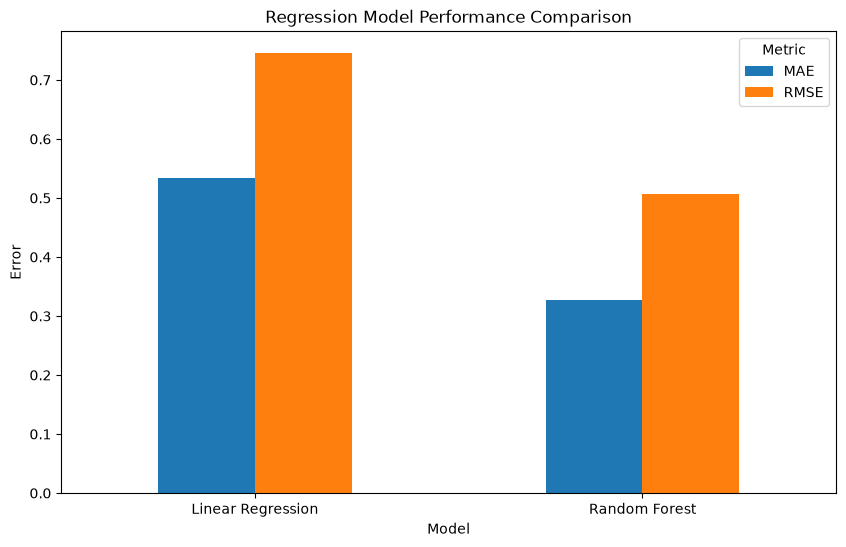

In [19]:
# Visual comparison of model performance

results.set_index("Model")[["MAE", "RMSE"]].plot(
    kind="bar",
    figsize=(10, 6)
)

plt.title("Regression Model Performance Comparison")
plt.ylabel("Error")
plt.xlabel("Model")
plt.xticks(rotation=0)
plt.legend(title="Metric")

plt.show()

### 5.3 Actual vs Predicted Values

The scatter plot compares actual house values with the values predicted by the Random Forest model.

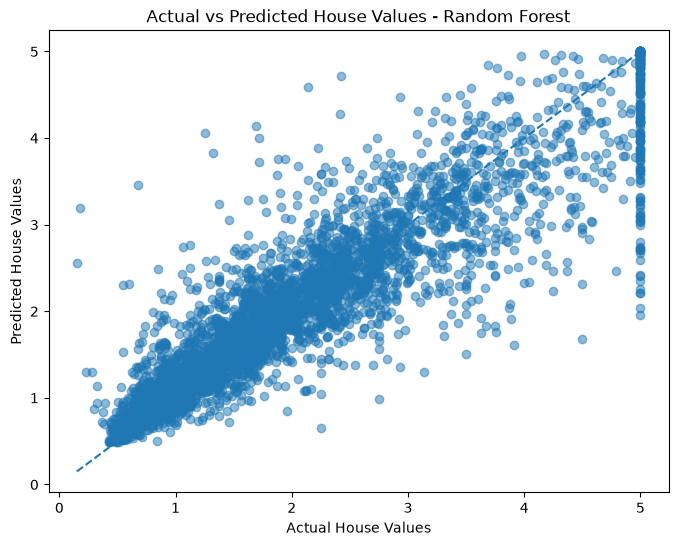

In [21]:
# Actual vs Predicted values for Random Forest

plt.figure(figsize=(8, 6))

plt.scatter(y_test, rf_predictions, alpha=0.5)

plt.xlabel("Actual House Values")
plt.ylabel("Predicted House Values")
plt.title("Actual vs Predicted House Values - Random Forest")

plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    linestyle="--"
)

plt.show()

# Conclusion

In this project, two regression models were trained to predict median house values using the California Housing dataset.

The models evaluated were:

- Linear Regression
- Random Forest Regressor

The models were evaluated using Mean Absolute Error (MAE) and Root Mean Squared Error (RMSE).

Based on the test-set results, the Random Forest model produced lower MAE and RMSE values than Linear Regression. This indicates that the Random Forest model made smaller prediction errors on this test dataset.

The project demonstrated the complete baseline regression workflow, including dataset loading, exploratory data analysis, train-test splitting, model training, prediction, evaluation, and visualization.

# Conclusion

In this project, two regression models were trained to predict median house values using the California Housing dataset.

The models evaluated were:

- Linear Regression
- Random Forest Regressor

The models were evaluated using Mean Absolute Error (MAE) and Root Mean Squared Error (RMSE).

Based on the test-set results, the Random Forest model produced lower MAE and RMSE values than Linear Regression. This indicates that the Random Forest model made smaller prediction errors on this test dataset.

The project demonstrated the complete baseline regression workflow, including dataset loading, exploratory data analysis, train-test splitting, model training, prediction, evaluation, and visualization.